**Sommaire**<a id='toc0_'></a>    
  - [Gestion de l'environnement de travail](#toc1_1_1_)    
  - [Extraction des données](#toc1_2_)    
    - [Departments](#toc1_2_1_)    
  - [Variable selection](#toc1_3_)    
    - [Concatenation of both datasets.](#toc1_3_1_)    
  - [Cleaning data (missing values and outliers)](#toc1_4_)    
    - [Années](#toc1_4_1_)    
    - [Cout 5 usages](#toc1_4_2_)    
    - [type_energie_principale_chauffage](#toc1_4_3_)    
    - [surface_habitable_logement](#toc1_4_4_)    
    - [hauteur_sous_plafond](#toc1_4_5_)    
    - [nombre_niveau_logement](#toc1_4_6_)    
    - [type_batiment](#toc1_4_7_)    
    - [code_insee](#toc1_4_8_)    
    - [department](#toc1_4_9_)    
  - [Checking the final data frame after cleaning values.](#toc1_5_)    
  - [Extracting lat and long from the "_geopoint" column.](#toc1_6_)    
  - [Mapping climate area](#toc1_7_)    
  - [Adding altitude](#toc1_8_)    
    - [Preparing the data for mapping altitude values.](#toc1_8_1_)    
    - [Merging](#toc1_8_2_)    
  - [Final check and writing .csv](#toc1_8_3_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

Corrections géographiques intégrées de Nouhayla : les codes de Lyon et Pierre-Bénite sont corrigés uniquement pour la jointure d'altitude. Les zones H1/H2/H3 sont conservées. L'export sauvegarde le CSV antérieur et sépare la traçabilité des variables ML. Les modèles existants restent associés au CSV antérieur jusqu'à réentraînement explicite.


### <a id='toc1_1_1_'></a>[Gestion de l'environnement de travail](#toc0_)

In [1]:
# Variable globale pour exécuter ou non les blocs de code d’extraction.
EXTRACTION = False

In [ ]:
from pathlib import Path
import os
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists() and (p / "MLmodels").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Ouvrez le notebook depuis le dépôt App_Enedis.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Racine du projet :", ROOT)

REFERENCE_YEAR = 2026  # Année utilisée par le CSV et le modèle conservés.
# Import des packages
import datetime as dt

import matplotlib.pyplot as plt

# import des librairies.
import pandas as pd

from helpers.api_requesters import Ademe_API_requester

## <a id='toc1_2_'></a>[Extraction des données](#toc0_)

In [3]:
# Initialisation de l'API requester
ademe = Ademe_API_requester()

### <a id='toc1_2_1_'></a>[Departments](#toc0_)

In [4]:
if EXTRACTION:
    # Fetching number of datapoints per department.
    departments_old = pd.DataFrame(ademe.get_all_departments_count(neuf=False)).drop(
        columns=["results"]
    )
    departments_new = pd.DataFrame(ademe.get_all_departments_count(neuf=True)).drop(
        columns=["results"]
    )

    # Renaming and reorganizing columns
    departments_old = departments_old.rename(columns={"value": "department"})[
        ["department", "total"]
    ]
    departments_new = departments_new.rename(columns={"value": "department"})[
        ["department", "total"]
    ]

    # Get rid of departments from Corse and Outer-seas.
    departments_old = departments_old[~departments_old["department"].isin(["2A", "2B"])]
    departments_old = departments_old[
        ~departments_old["department"].apply(lambda x: len(x) > 2)
    ]
    departments_new = departments_new[~departments_new["department"].isin(["2A", "2B"])]
    departments_new = departments_new[
        ~departments_new["department"].apply(lambda x: len(x) > 2)
    ]

In [5]:
if EXTRACTION:
    # Verify that both dataframes contain the same departments.
    all(departments_old["department"].isin(departments_new["department"]))

In [6]:
if EXTRACTION:
    # Get a list of all departments.
    departments_list = departments_old["department"].tolist()

    # Nombre de département
    print(len(departments_list))

Décommentez la cellule suivante pour l’extraction.

In [7]:
if EXTRACTION:
    data_old = []
    data_new = []

    # Request old data for all departments and write the result to a csv file.
    for i, department in enumerate(departments_list):
        print(
            f"Requesting data for department {department} ({i + 1}/{len(departments_list)})"
        )

        print("Old housing:")
        result = ademe.custom_lines_request(
            neuf=False, qs=f"code_departement_ban:{department}", limit=5000
        )

        # Add the data to the list
        data_old.extend(result)

        # Same on
        print("New housing:")
        result_new = ademe.custom_lines_request(
            neuf=True, qs=f"code_departement_ban:{department}", limit=5000
        )

        # Add the data to the list
        data_new.extend(result_new)

    # Convert the data to a dataframe
    df_old = pd.DataFrame(data_old)
    df_new = pd.DataFrame(data_new)

    # Write the dataframe to a csv file.
    df_old.to_csv("data/ademe_data_old.csv", index=False)
    df_new.to_csv("data/ademe_data_new.csv", index=False)

## <a id='toc1_3_'></a>[Selection de variables](#toc0_)

**Objectif**: générer un échantillon d’entraînement et de test, représentatif de toutes les étiquettes DPE, réparties dans toutes les régions.

### <a id='toc1_3_1_'></a>[Concatenation of both datasets.](#toc0_)

In [ ]:
from src.data_lineage import RAW_FIELDS
# Lire les anciens fichiers.
df_old = pd.read_csv("data/ademe_data_old.csv", low_memory=False, dtype={name: "string" for name in RAW_FIELDS})

In [9]:
df_old.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 470000 entries, 0 to 469999
Columns: 228 entries, configuration_installation_chauffage_n1 to facteur_couverture_solaire_saisi_installation_chauffage_n2
dtypes: float64(122), int64(8), object(98)
memory usage: 817.6+ MB


In [ ]:
from src.data_lineage import RAW_FIELDS
# Lire les nouveaux fichiers
df_new = pd.read_csv("data/ademe_data_new.csv", low_memory=False, dtype={name: "string" for name in RAW_FIELDS})

In [11]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364959 entries, 0 to 364958
Columns: 196 entries, numero_voie_ban to conso_refroidissement_annuel
dtypes: float64(104), int64(8), object(84)
memory usage: 545.7+ MB


In [ ]:
# Ajouter une année de construction pour les nouveaux logements.
df_new["annee_construction"] = REFERENCE_YEAR

In [ ]:
# Préserver la provenance avant la concaténation ; jamais une entrée des modèles.
from src.data_lineage import RAW_FIELDS, LINEAGE_FIELDS
for source, raw in [("existant", df_old), ("neuf", df_new)]:
    raw["_source_dataset"] = source
    raw["_source_row"] = raw.index
df_total = pd.concat([df_old, df_new]).reset_index(drop=True)


In [14]:
# Vérification des index dupliqués.
df_total.index.duplicated().any()

np.False_

In [15]:
# Nombre de logements dans le dataframe total.
len(df_total)

834959

Text(0.5, 1.0, 'Distribution of DPE labels in the dataset')

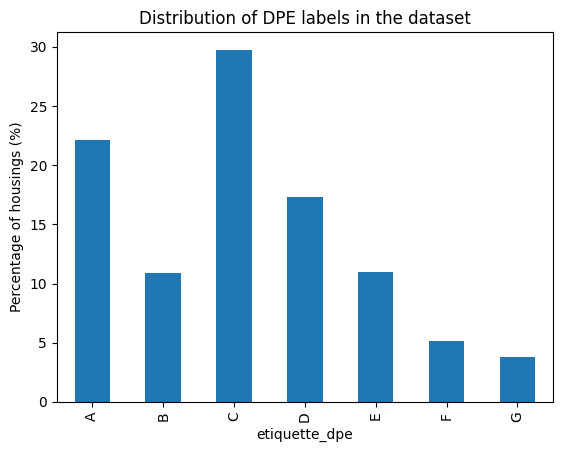

In [16]:
# Comptage par label DPE
(df_total["etiquette_dpe"].value_counts(normalize=True).sort_index() * 100).plot.bar()
plt.ylabel("Percentage of housings (%)")
plt.title("Distribution of DPE labels in the dataset")

In [17]:
# Répartition des départements.
df_total["code_departement_ban"].value_counts(normalize=True).sort_index().min()

np.float64(0.006188327810108041)

In [18]:
df_total["code_departement_ban"].value_counts(normalize=True).sort_index().max()

np.float64(0.011976635978533077)

-> Les départements sont assez uniformément répartis (un facteur d’environ ×2 entre le minimum et le maximum).

In [19]:
# Exporter la liste des colonnes.
df_total.columns.tolist()

['configuration_installation_chauffage_n1',
 'conso_chauffage_installation_chauffage_n1',
 'type_generateur_n1_ecs_n1',
 'numero_voie_ban',
 'score_ban',
 'surface_habitable_immeuble',
 'conso_auxiliaires_ep',
 'deperditions_murs',
 'cout_eclairage',
 'conso_auxiliaires_ef',
 'statut_geocodage',
 'ventilation_posterieure_2012',
 'cout_chauffage',
 'conso_5_usages_par_m2_ep',
 'date_etablissement_dpe',
 'conso_ecs_ef_energie_n1',
 'conso_ecs_ef_energie_n2',
 'emission_ges_chauffage',
 'description_installation_chauffage_n1',
 'conso_5_usages_par_m2_ef',
 'cout_ecs_energie_n2',
 'conso_chauffage_ef_energie_n1',
 'conso_chauffage_ef_energie_n2',
 'qualite_isolation_menuiseries',
 'cout_total_5_usages_energie_n2',
 'date_reception_dpe',
 'cout_total_5_usages_energie_n1',
 'cout_ecs_energie_n1',
 'qualite_isolation_plancher_bas',
 'modele_dpe',
 'qualite_isolation_enveloppe',
 'conso_chauffage_generateur_n1_installation_n1',
 'type_energie_n1',
 'emission_ges_eclairage',
 'type_energie_n2',

In [72]:
# Liste des caractéristiques pertinentes pour le modèle.
# Ne conserver que les caractéristiques avec des valeurs manquantes < 10% et pertinentes pour le modèle.
# EP = énergie primaire
# EF = énergie finale
# ecs = eau chaude sanitaire
#
features = [
    # ----------------------- Classic costs
    "cout_total_5_usages",  # --> OK
    "type_energie_principale_chauffage",  # --> OK
    # "type_energie_principale_ecs",   # ---> Trop de valeurs "autres" (65%)
    # "cout_chauffage",
    # "cout_eclairage",
    # "cout_refroidissement",
    # "cout_auxiliaires",
    # "cout_ecs",
    # "qualite_isolation_menuiseries",
    # "qualite_isolation_plancher_bas",
    # "qualite_isolation_enveloppe",  # --> ok
    # "qualite_isolation_murs",
    # "ubat_w_par_m2_k",
    # # ----------------------- ep costs
    # "conso_5_usages_ep",
    # "conso_5_usages_par_m2_ep",
    # "conso_chauffage_ep",
    # "conso_eclairage_ep",
    # "conso_auxiliaires_ep",
    # "conso_ecs_ep",
    # # ----------------------- ef costs
     "conso_5_usages_ef",
    # "conso_5_usages_par_m2_ef",
    # "conso_chauffage_ef",
    # "conso_eclairage_ef",
    # "conso_auxiliaires_ef",
    # "conso_ecs_ef",
    # "conso_refroidissement_ef",
    # # ----------------------- n-1 costs (year -1) To be ignored ? Mean ?
    # "cout_total_5_usages_energie_n1",
    # "cout_chauffage_energie_n1",
    # "cout_ecs_energie_n1",
    # "conso_5_usages_ef_energie_n1",
    # "conso_ecs_ef_energie_n1",
    # "conso_chauffage_ef_energie_n1",
    # "type_energie_n1",
    # ----------------------- Building characteristics
    "surface_habitable_logement",  # ---> Ok
    # "hauteur_sous_plafond",  # -----> Ok
    "nombre_niveau_logement",  # ----> Ok drop na
    "type_batiment",  # ----> Ok
    "annee_construction",  # -> Nan éliminés
    # ----------------------- Location features
    "code_insee_ban",
    # "code_region_ban",
    "code_departement_ban",  # ----> Ok, not usefull.
    # ----------------------- Target variable
    "etiquette_dpe",
    # ----------------------- Other needed variables
    "nom_commune_ban",
    "code_postal_ban",
]

In [73]:
# Nombre de features sélectionnées.
len(features)

12

In [ ]:
# Les colonnes de traçabilité seront jointes après le nettoyage.
df = df_total[features].copy()


En étudiant les données, voici les variables contenant plus de 1 % de valeurs manquantes ::
- qualite_isolation_plancher_bas (5%)
- nombre_niveau_logement (6%)
- année construction (9%)


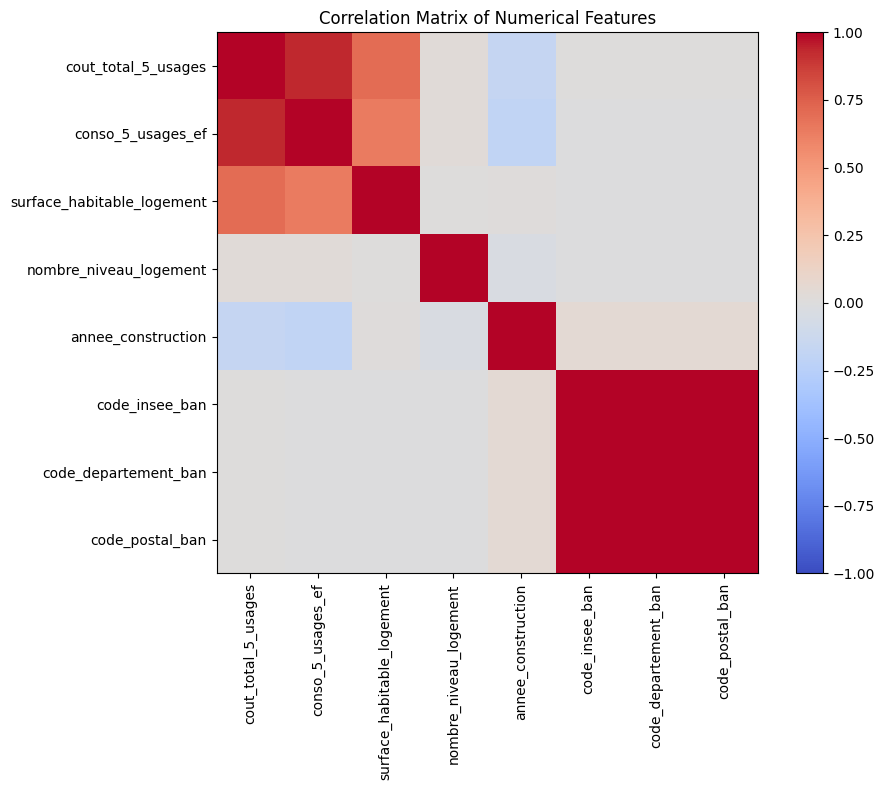

In [75]:
# Calculer la corrélation entre les colonnes numériques
numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()
labels = correlation_matrix.columns

# Afficher la matrice
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

fig.colorbar(image, ax=ax)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_title("Correlation Matrix of Numerical Features")

fig.tight_layout()
plt.show()

## <a id='toc1_4_'></a>[Nettoyage des données (valeurs manquantes et valeurs aberrantes))](#toc0_)

### <a id='toc1_4_1_'></a>[Années](#toc0_)

Eliminer les valeurs manquantes, transformer la variable année en "age" pour faciliter le calcul du modèle.

In [76]:
df = df.dropna(subset=["annee_construction"])

<Axes: xlabel='etiquette_dpe'>

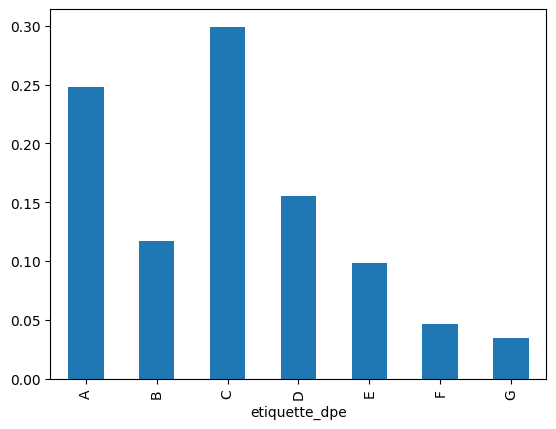

In [77]:
# Verification de la distribution.
df["etiquette_dpe"].value_counts(normalize=True).sort_index().plot(kind="bar")

In [ ]:
# Remplacer par l'âge du bâtiment.
current_year = REFERENCE_YEAR
df.loc[:, "age_batiment"] = current_year - df.loc[:, "annee_construction"]
df.drop(columns=["annee_construction"], inplace=True)

In [79]:
# Supprimer toutes les valeurs négatives.
df = df[df["age_batiment"] >= 0]

<Axes: ylabel='Frequency'>

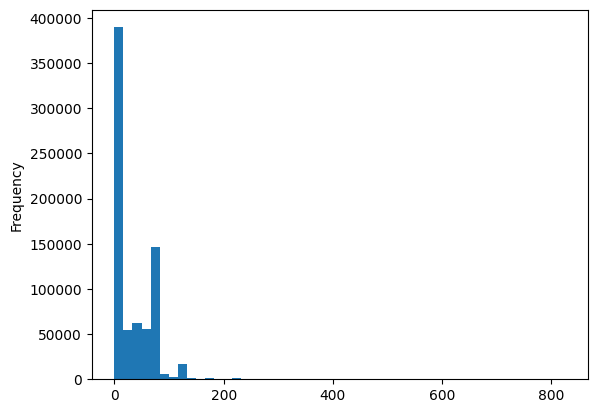

In [80]:
# checker les valeurs.
df["age_batiment"].plot(kind="hist", bins=50)

### <a id='toc1_4_2_'></a>[Cout 5 usages](#toc0_)

In [81]:
# Elimlination de 125 points de données.
df = df.dropna(subset=["cout_total_5_usages"])

In [82]:
# Suppression des lignes aberrantes (méthode de l'inter-quartile).
Q1 = df["cout_total_5_usages"].quantile(0.25)
Q3 = df["cout_total_5_usages"].quantile(0.75)
IQR = Q3 - Q1

# Filtering the dataframe
df = df[
    (df["cout_total_5_usages"] >= Q1 - 1.5 * IQR)
    & (df["cout_total_5_usages"] <= Q3 + 1.5 * IQR)
]

<Axes: ylabel='Frequency'>

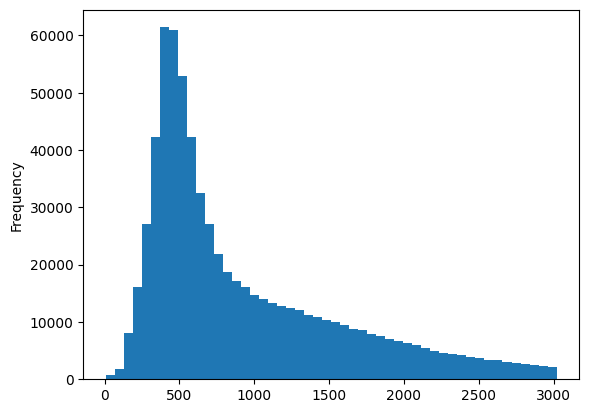

In [83]:
# checker les valeurs.
df["cout_total_5_usages"].plot(kind="hist", bins=50)

### <a id='toc1_4_3_'></a>[type_energie_principale_chauffage](#toc0_)

In [84]:
# Pas de valeurs nulles.
df["type_energie_principale_chauffage"].isna().sum()

np.int64(0)

In [85]:
# Distribution.
chauffage_distribution = (
    df["type_energie_principale_chauffage"].value_counts(normalize=True) * 100
)

chauffage_distribution

type_energie_principale_chauffage
Électricité                                                     63.044145
Gaz naturel                                                     25.632081
Réseau de Chauffage urbain                                       5.429225
Fioul domestique                                                 1.597095
Bois – Granulés (pellets) ou briquettes                          1.571340
Bois – Bûches                                                    1.500297
Non affecté                                                      0.518716
GPL                                                              0.399780
Propane                                                          0.110399
Électricité d'origine renouvelable utilisée dans le bâtiment     0.109097
Bois – Plaquettes forestières                                    0.067136
Bois – Plaquettes d’industrie                                    0.011141
Charbon                                                          0.006511
Buta

In [86]:
threshold = 6

# Obtenir la list de toutes les modalités n'atteignant pas le seuil.
rare_modalities = chauffage_distribution[
    chauffage_distribution < threshold
].index.tolist()

# Remplacer les modalités rares par "Autre" dans le dataframe.
df.loc[:, "type_energie_principale_chauffage"] = df[
    "type_energie_principale_chauffage"
].replace(rare_modalities, "Autre")

In [87]:
# Checker la distribution.
df["type_energie_principale_chauffage"].value_counts(normalize=True) * 100

type_energie_principale_chauffage
Électricité    63.044145
Gaz naturel    25.632081
Autre          11.323774
Name: proportion, dtype: float64

### <a id='toc1_4_4_'></a>[surface_habitable_logement](#toc0_)

In [88]:
# Vérifier les valeurs manquantes.
df["surface_habitable_logement"].isna().sum()

np.int64(4316)

In [89]:
# Utiliser la méthode interquartile pour éliminer les valeurs aberrantes (et les valeurs manquantes).
Q1 = df["surface_habitable_logement"].quantile(0.25)
Q3 = df["surface_habitable_logement"].quantile(0.75)
IQR = Q3 - Q1

# Filtering the dataframe
df = df[
    (df["surface_habitable_logement"] >= Q1 - 1.5 * IQR)
    & (df["surface_habitable_logement"] <= Q3 + 1.5 * IQR)
]

In [90]:
# Vérifier les valeurs manquantes.
df["surface_habitable_logement"].isna().sum()

np.int64(0)

### <a id='toc1_4_6_'></a>[nombre_niveau_logement](#toc0_)

In [91]:
# Supprimer les valeurs manquantes.
df = df.dropna(subset=["nombre_niveau_logement"])

<Axes: ylabel='Frequency'>

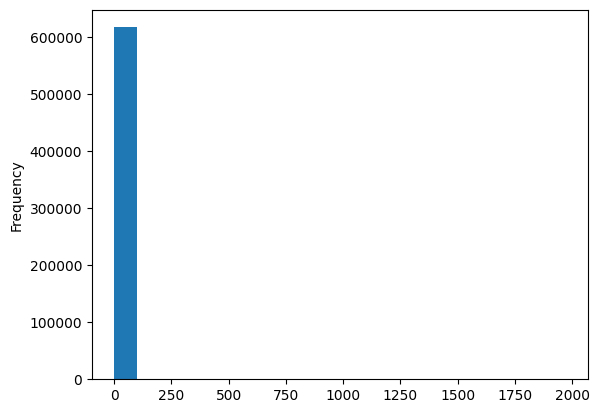

In [92]:
# Checker les distributions.
df["nombre_niveau_logement"].plot(kind="hist", bins=20)

In [93]:
# Vérifier les outliers.
df = df[(df["nombre_niveau_logement"] >= 1) & (df["nombre_niveau_logement"] <= 10)]

<Axes: ylabel='Frequency'>

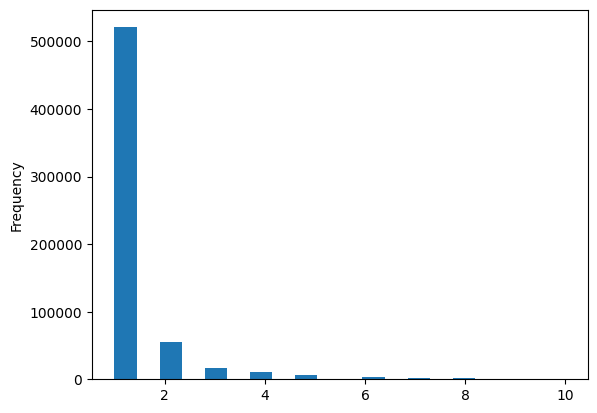

In [94]:
# checker la distribution des niveaux.
df["nombre_niveau_logement"].plot(kind="hist", bins=20)

### <a id='toc1_4_7_'></a>[type_batiment](#toc0_)

In [95]:
# checker les valeurs manquantes.
df["type_batiment"].isna().sum()

np.int64(0)

In [96]:
# checker la distribution.
df["type_batiment"].value_counts(normalize=True) * 100

type_batiment
appartement    53.55722
maison         46.35610
immeuble        0.08668
Name: proportion, dtype: float64

### <a id='toc1_4_8_'></a>[code_insee](#toc0_)

In [97]:
# Changer le type du code_insee en string.
df["code_insee_ban"] = df["code_insee_ban"].astype(str)

# Ajouter un 0 au début du code insee si celui-ci est trop court.
df["code_insee_ban"] = df["code_insee_ban"].apply(lambda x: x.zfill(5))

### <a id='toc1_4_9_'></a>[department](#toc0_)

In [98]:
# Ajouter un 0 au début des codes de département qui sont trop courts.
df["code_departement_ban"] = df["code_departement_ban"].astype(str)
df["code_departement_ban"] = df["code_departement_ban"].apply(lambda x: x.zfill(2))

In [99]:
# verifier la longueur des codes de département.
df["code_departement_ban"].str.len().value_counts()

code_departement_ban
2    616057
Name: count, dtype: int64

## <a id='toc1_5_'></a>[Vérification du data frame final après le nettoyage des valeurs.](#toc0_)

In [100]:
# Nombre d'observations.
len(df)

616057

<Axes: xlabel='etiquette_dpe'>

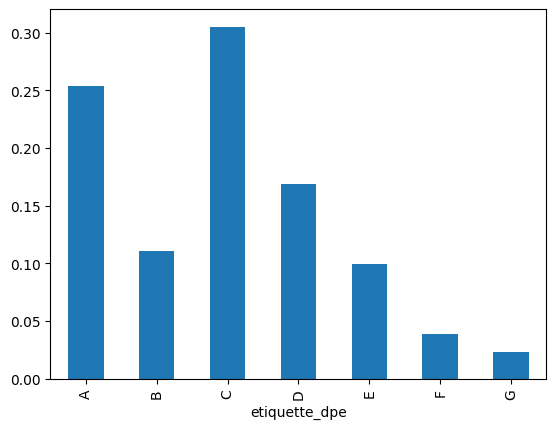

In [101]:
# Répartition DPE.
df["etiquette_dpe"].value_counts(normalize=True).sort_index().plot(kind="bar")

## <a id='toc1_6_'></a>[Extraction de la latitude et de la longitude à partir de la colonne _geopoint.](#toc0_)

In [102]:
# Extraction de la colonne _geopoint en latitude et longitude.
df_total[["lat", "lon"]] = pd.DataFrame(
    df_total["_geopoint"].str.split(",", expand=True)
)

# defragmentation de la dataframe.
df_total = df_total.copy()

In [103]:
df_total[["lat", "lon"]]

,lat,lon
0,48.82779300100895,2.3737170147307167
1,48.891459971807365,2.3483300483294514
2,48.87487395641234,2.39380403972456
3,48.825799005332485,2.3780779665295646
4,48.830526032846976,2.2975909653308135
...,...,...
834954,44.63589403255707,3.4797770271122683
834955,44.5335510048487,3.466790989842102
834956,44.46544595586627,3.3405030105582494
834957,44.5340780159921,3.465957999148411


In [ ]:
# Les index d'origine sont encore conservés : jointures 1:1 avec les bruts.
df = df.join(df_total[["lat", "lon"]], how="left", validate="one_to_one")
df = df.join(df_total[LINEAGE_FIELDS], how="left", validate="one_to_one")


In [105]:
# Vérifier les lignes sans coordonnées.
df["lon"].isna().any() or df["lat"].isna().any()

np.False_

## <a id='toc1_7_'></a>[Cartographie de la zone climatique](#toc0_)

In [106]:
H1 = [
    "01",
    "02",
    "03",
    "05",
    "08",
    "10",
    "14",
    "15",
    "19",
    "21",
    "23",
    "25",
    "27",
    "28",
    "38",
    "39",
    "42",
    "43",
    "45",
    "51",
    "52",
    "54",
    "55",
    "57",
    "58",
    "59",
    "60",
    "61",
    "62",
    "63",
    "67",
    "68",
    "69",
    "70",
    "71",
    "73",
    "74",
    "75",
    "76",
    "77",
    "78",
    "80",
    "87",
    "88",
    "89",
    "90",
    "91",
    "92",
    "93",
    "94",
    "95",
]

H2 = [
    "04",
    "07",
    "09",
    "12",
    "16",
    "17",
    "18",
    "22",
    "24",
    "26",
    "29",
    "31",
    "32",
    "33",
    "35",
    "36",
    "37",
    "40",
    "41",
    "44",
    "46",
    "47",
    "48",
    "49",
    "50",
    "53",
    "56",
    "64",
    "65",
    "72",
    "79",
    "81",
    "82",
    "84",
    "85",
    "86",
]

H3 = ["06", "11", "13", "20", "30", "34", "66", "83"]

In [107]:
# Codage des zones climatiques.
df.loc[df["code_departement_ban"].isin(H1), "zone_climatique"] = "H1"
df.loc[df["code_departement_ban"].isin(H2), "zone_climatique"] = "H2"
df.loc[df["code_departement_ban"].isin(H3), "zone_climatique"] = "H3"

In [108]:
# verification de la répartition des zones climatiques.
print(len(df[df["zone_climatique"] == "H1"]))
print(len(df[df["zone_climatique"] == "H2"]))
print(len(df[df["zone_climatique"] == "H3"]))

323667
243551
48839


In [109]:
# Missing values?
df["zone_climatique"].isna().sum()

np.int64(0)

## <a id='toc1_8_'></a>[Ajout altitude](#toc0_)

### <a id='toc1_8_1_'></a>[Préparation des données pour la cartographie des valeurs d’altitude.](#toc0_)

In [ ]:
# Réutiliser le fichier local ; aucun téléchargement automatique.
chemin = Path("data/communes-france-2025.csv")
if not chemin.is_file():
    raise FileNotFoundError(f"Table des communes absente : {chemin}")
print("Table locale :", chemin)


In [111]:
cities = pd.read_csv(
    "data/communes-france-2025.csv",
    dtype={"code_insee": str, "dep_code": str},
    low_memory=False
)

cities["code_insee"] = cities["code_insee"].str.zfill(5)
cities["dep_code"] = cities["dep_code"].str.zfill(2)

In [112]:
# groupe par département et prendre la moyenne de l'altitude.
departments = cities.groupby("dep_code")["altitude_moyenne"].mean()

In [113]:
# Isolation des colonnes de fusion.
cities = cities[["code_insee", "altitude_moyenne"]]

In [114]:
# verification des clés dupliquées pour la fusion.
cities["code_insee"].duplicated().any()

np.False_

### <a id='toc1_8_2_'></a>[Fusion des données](#toc0_)

In [ ]:
# Corrections de Nouhayla : Lyon et Pierre-Bénite, sur une clé séparée.
# La fonction vérifie l'unicité des communes, l'effectif et l'ordre des logements.
from src.preparation_geography import join_commune_altitudes
df = join_commune_altitudes(df, cities)


In [ ]:
# Altitudes sans correspondance communale : repli départemental conservé.
missing = df[df["altitude_moyenne"].isna()].drop(columns=["altitude_moyenne"])


In [117]:
# Complétion des valeurs d'altitude manquantes à l'aide de la moyenne d'altitude par département.
missing = missing.merge(
    departments, left_on="code_departement_ban", right_index=True, how="left"
)

# verification des valeurs d'altitude manquantes encore présentes.
missing["altitude_moyenne"].isna().sum()

np.int64(0)

In [118]:
# Compléter les valeurs manquantes dans le dataframe principal.
df["altitude_moyenne"] = df["altitude_moyenne"].fillna(
    df["code_departement_ban"].map(departments)
)

In [119]:
# verification des valeurs manquantes.
df["altitude_moyenne"].isna().sum()

np.int64(0)

In [ ]:
# Les clés techniques ne sont pas des caractéristiques ML.
df.drop(columns=["code_insee", "code_insee_jointure"], inplace=True)


## <a id='toc1_8_3_'></a>[Vérification finale et écriture du fichier .csv](#toc0_)

In [121]:
# Checking
df

,cout_total_5_usages,type_energie_principale_chauffage,conso_5_usages_ef,surface_habitable_logement,nombre_niveau_logement,type_batiment,code_insee_ban,code_departement_ban,etiquette_dpe,nom_commune_ban,code_postal_ban,age_batiment,lat,lon,zone_climatique,altitude_moyenne
0,946.3,Autre,9715.3,58.0,1.0,appartement,75115,75,C,Paris,75015.0,57.0,48.830526032846976,2.2975909653308135,H1,35.0
1,724.5,Électricité,3970.4,30.0,1.0,appartement,75113,75,D,Paris,75013.0,79.0,48.82544898520057,2.3464919595161677,H1,35.0
2,761.6,Électricité,3075.3,10.8,1.0,appartement,75117,75,F,Paris,75017.0,51.0,48.881599040702966,2.2882210641288476,H1,35.0
3,946.8,Électricité,6803.0,70.0,1.0,appartement,75112,75,C,Paris,75012.0,78.0,48.836409960977946,2.386896058492526,H1,35.0
4,1246.0,Électricité,5571.8,34.7,1.0,appartement,75105,75,E,Paris,75005.0,392.0,48.84818996361827,2.351271027197886,H1,35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
616052,879.2,Autre,5444.0,93.7,1.0,maison,48140,48,B,Saint-Chély-d'Apcher,48200.0,0.0,44.79340195579948,3.2652009875332535,H2,1026.0
616053,514.0,Autre,1878.9,89.9,1.0,maison,48127,48,A,Monts-de-Randon,48700.0,0.0,44.63589403255707,3.4797770271122683,H2,1224.0
616054,518.0,Autre,1893.9,124.6,1.0,maison,48095,48,A,Mende,48000.0,0.0,44.5335510048487,3.466790989842102,H2,899.0
616055,568.3,Autre,2164.5,96.2,1.0,maison,48095,48,A,Mende,48000.0,0.0,44.5340780159921,3.465957999148411,H2,899.0


In [ ]:
# Sauvegarder le CSV précédent avant de remplacer la version commune.
# Les identifiants et dates sont exportés dans un fichier de traçabilité séparé.
from src.preparation_geography import export_prepared
manifest = export_prepared(df)
print("Version des données :", manifest["version"])


# Création d’une agrégation de toutes les villes avec leurs coordonnées.

In [ ]:
# Agrégation API facultative, désactivée par défaut.
if EXTRACTION:
    ademe = Ademe_API_requester()


In [ ]:
# Agrégation API facultative, désactivée par défaut.
if EXTRACTION:
    cities = pd.read_csv("data/communes-france-2025.csv", low_memory=False)


In [ ]:
# Agrégation API facultative, désactivée par défaut.
if EXTRACTION:
    cities["code_insee_centre_zone_emploi"]


In [ ]:
# Agrégation API facultative, désactivée par défaut.
if EXTRACTION:
    # Obtenir la list de tous les codes insee.
    codes = cities["code_insee"].tolist()
    codes.extend(cities["code_insee_centre_zone_emploi"].dropna().tolist())
    codes = list(set(codes))
    
    # Fractionner la liste 'codes' en blocs de 100 éléments
    chunks = [codes[i:i + 100] for i in range(0, len(codes), 100)]


In [ ]:
# Agrégation API facultative, désactivée par défaut.
if EXTRACTION:
    n = len(chunks)
    
    old = list()
    new = list()
    
    
    
    # Requête des données anciennes pour tous les départements et écriture du résultat dans un fichier csv.
    for i, codes in enumerate(chunks):
        print(
            f"Requesting data for chunk {i + 1}/{n}"
        )
    
        # concatenated codes:
        str_codes = "|".join(codes)
    
        total = 0
        consumption = 0
    
        # Get the aggregation for old housings.
        data_old = ademe.custom_agg_request(
            neuf=False, field="code_insee_ban", q_fields="code_insee_ban", q=str_codes, metric_field="cout_total_5_usages", metric="sum"
        )
    
        data_new = ademe.custom_agg_request(
            neuf=True, field="code_insee_ban", q_fields="code_insee_ban", q=str_codes, metric_field="cout_total_5_usages", metric="sum"
        )
    
        print(data_old)
        print(data_new)
    
        old = old + data_old
        new = new + data_new
    
    
    df_old = pd.DataFrame(old)
    df_new = pd.DataFrame(new)
    
    df = df_old
    df["metric"] = df["metric"] + df_new["metric"]
    df.dropna(subset=["metric"], inplace=True)
    df = df.drop(columns=["results"])
    df = df.astype({"metric": int})
    
    df.rename(columns={"value": "code_insee", "metric": "cout_5_usages"}, inplace=True)
    
    # Write the file to a csv.
    df.to_csv("output/insee_grouping_beforemerge.csv", index=False)


## Jointure avec d’autres informations

In [ ]:
# Agrégation API facultative, désactivée par défaut.
if EXTRACTION:
    df = pd.read_csv("output/insee_grouping_beforemerge.csv", low_memory=False)
    cities = pd.read_csv("data/communes-france-2025.csv", low_memory=False)


In [ ]:
# Agrégation API facultative, désactivée par défaut.
if EXTRACTION:
    df_merged = df.merge(cities, left_on="code_insee", right_on="code_insee", how="left")


---

In [ ]:
# Agrégation API facultative, désactivée par défaut.
if EXTRACTION:
    # selection des columns.
    df_merged = df_merged[["code_insee","cout_5_usages", "altitude_moyenne", "latitude_centre", "longitude_centre", "total"]]


In [ ]:
# Agrégation API facultative, désactivée par défaut.
if EXTRACTION:
    df.to_csv("output/insee_grouping.csv", index=False)
